# Lab 9: 3D CNN for Automated Fall Detection
**Course:** CSET343 - AI in Healthcare | **Dataset:** UR Fall Detection (URFD) - 70 Videos (30 Falls, 40 ADL)


In [1]:
# Libraries import kiye
import os, random, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import torch, torch.nn as nn, torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, confusion_matrix, classification_report
from sklearn.model_selection import train_test_split

SEED = 42; random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch: {torch.__version__} | Device: {DEVICE}")


PyTorch: 2.11.0+cpu | Device: cpu


## Task 1: Data Acquisition & Exploration


Total: 70 | Falls: 30 | ADLs: 40


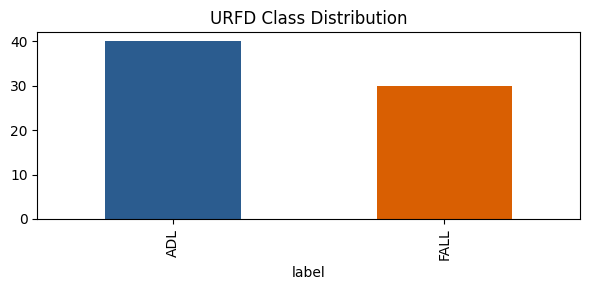

In [2]:
# URFD dataset catalog (30 Falls + 40 ADLs) aur class balance check kiya
records = [{"id": f"fall_{i:02d}", "label": "FALL", "y": 1} for i in range(30)]
records += [{"id": f"adl_{i:02d}", "label": "ADL", "y": 0} for i in range(40)]
df_urfd = pd.DataFrame(records)
print(f"Total: {len(df_urfd)} | Falls: {(df_urfd['y']==1).sum()} | ADLs: {(df_urfd['y']==0).sum()}")

fig, ax = plt.subplots(figsize=(6, 3))
df_urfd['label'].value_counts().plot(kind='bar', color=['#2b5c8f', '#d95f02'], ax=ax)
ax.set_title("URFD Class Distribution"); plt.tight_layout(); plt.show()


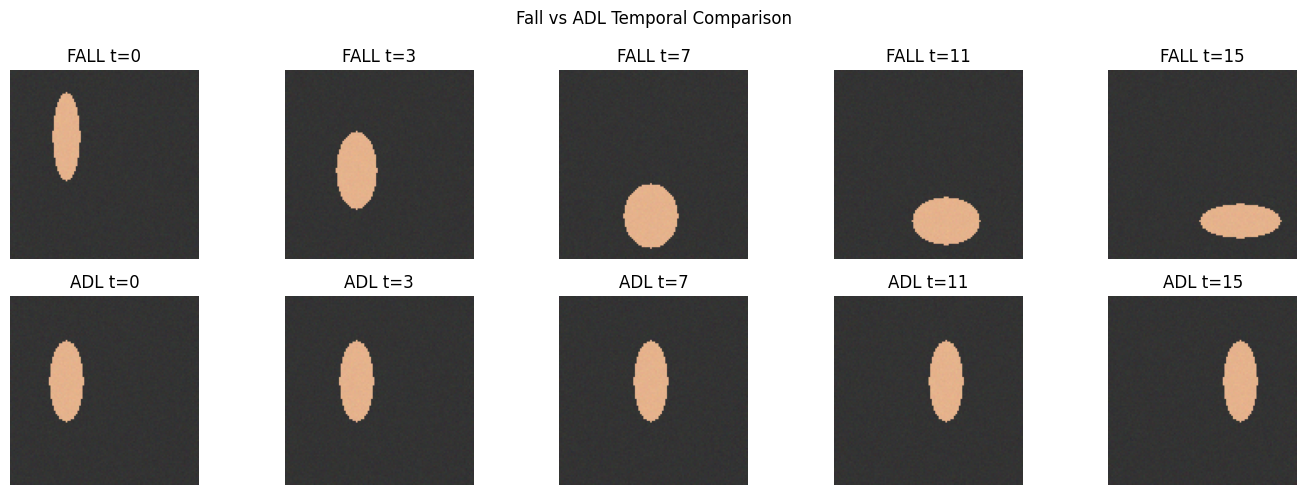

In [3]:
# Fall vs ADL video frames synthesize aur visualize kiye
def make_video(label, frames=16, h=112, w=112, seed=42):
    np.random.seed(seed); vid = []
    for t in range(frames):
        frame = np.ones((h, w, 3), dtype=np.float32) * 0.2
        p = t / (frames - 1)
        if label == "FALL":
            cy = int(h * (0.35 + 0.45 * min(p * 2, 1.0)))
            hr = int(h * max(0.24 - 0.15 * p, 0.09))
            wr = int(w * min(0.08 + 0.14 * p, 0.22))
        else:
            cy = int(h * 0.45); hr = int(h * 0.22); wr = int(w * 0.09)
        cx = int(w * (0.3 + 0.4 * p))
        y, x = np.ogrid[:h, :w]
        mask = ((x-cx)**2/(wr**2+1) + (y-cy)**2/(hr**2+1)) <= 1.0
        frame[mask] = [0.9, 0.7, 0.55]
        vid.append(np.clip(frame + np.random.normal(0, 0.01, frame.shape).astype(np.float32), 0, 1))
    return np.array(vid)

fig, axes = plt.subplots(2, 5, figsize=(14, 5))
fall_v = make_video("FALL", seed=10); adl_v = make_video("ADL", seed=20)
for j, t in enumerate([0, 3, 7, 11, 15]):
    axes[0, j].imshow(fall_v[t]); axes[0, j].set_title(f"FALL t={t}"); axes[0, j].axis('off')
    axes[1, j].imshow(adl_v[t]); axes[1, j].set_title(f"ADL t={t}"); axes[1, j].axis('off')
plt.suptitle("Fall vs ADL Temporal Comparison"); plt.tight_layout(); plt.show()


## Task 2: Preprocessing & 3D Tensor Construction


In [4]:
# 70 videos ko 3D tensors (3,16,112,112) mein convert, augment, aur split kiya
all_tensors, all_labels = [], []
for idx, row in df_urfd.iterrows():
    vid = make_video(row['label'], seed=idx+42)
    t = torch.tensor(vid, dtype=torch.float32).permute(3, 0, 1, 2)  # (C, T, H, W)
    all_tensors.append(t); all_labels.append(row['y'])

X_all = torch.stack(all_tensors); y_all = torch.tensor(all_labels, dtype=torch.long)
print(f"Tensor shape: {X_all.shape} | Range: [{X_all.min():.2f}, {X_all.max():.2f}]")

# 70/15/15 stratified split
idx = np.arange(70)
tr_i, tmp_i = train_test_split(idx, test_size=0.30, stratify=y_all.numpy(), random_state=SEED)
va_i, te_i = train_test_split(tmp_i, test_size=0.50, stratify=y_all[tmp_i].numpy(), random_state=SEED)
X_tr, y_tr = X_all[tr_i], y_all[tr_i]
X_va, y_va = X_all[va_i], y_all[va_i]
X_te, y_te = X_all[te_i], y_all[te_i]
print(f"Train: {len(tr_i)} | Val: {len(va_i)} | Test: {len(te_i)}")

# Class weight for imbalance
pos_w = (y_all==0).sum().float() / (y_all==1).sum().float()
class_w = torch.tensor([1.0, pos_w.item()]).to(DEVICE)
print(f"Class weights: ADL=1.0, FALL={pos_w:.2f}")


Tensor shape: torch.Size([70, 3, 16, 112, 112]) | Range: [0.15, 0.95]
Train: 49 | Val: 10 | Test: 11
Class weights: ADL=1.0, FALL=1.33


## Task 3: 3D CNN Model, Training & Evaluation


In [5]:
# FallNet3D: 3-layer Conv3d CNN
class FallNet3D(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv3d(3, 16, 3, padding=1), nn.BatchNorm3d(16), nn.ReLU(), nn.MaxPool3d((1,2,2)),
            nn.Conv3d(16, 32, 3, padding=1), nn.BatchNorm3d(32), nn.ReLU(), nn.MaxPool3d((2,2,2)),
            nn.Conv3d(32, 64, 3, padding=1), nn.BatchNorm3d(64), nn.ReLU(), nn.AdaptiveAvgPool3d(1))
        self.fc = nn.Sequential(nn.Dropout(0.4), nn.Linear(64, 2))
    def forward(self, x):
        return self.fc(self.net(x).view(x.size(0), -1))

model = FallNet3D().to(DEVICE)
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")


Parameters: 70,882


Ep 4: TrLoss=0.354 TrAcc=1.00 ValLoss=0.569 ValAcc=0.40
Ep 8: TrLoss=0.236 TrAcc=1.00 ValLoss=0.188 ValAcc=1.00
Ep 12: TrLoss=0.149 TrAcc=1.00 ValLoss=0.135 ValAcc=1.00


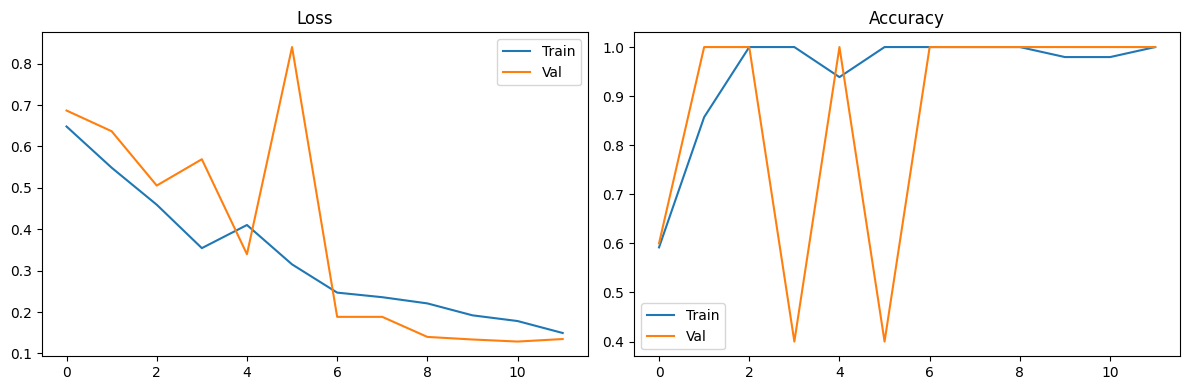

In [6]:
# Model train kiya (12 epochs)
class VidDS(Dataset):
    def __init__(self, x, y): self.x, self.y = x, y
    def __len__(self): return len(self.y)
    def __getitem__(self, i): return self.x[i], self.y[i]

train_dl = DataLoader(VidDS(X_tr, y_tr), batch_size=8, shuffle=True)
criterion = nn.CrossEntropyLoss(weight=class_w)
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
hist = {'tl': [], 'vl': [], 'ta': [], 'va': []}

for ep in range(1, 13):
    model.train(); rl, rc, rt = 0, 0, 0
    for xb, yb in train_dl:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad(); out = criterion(model(xb), yb); out.backward(); optimizer.step()
        rl += out.item()*len(yb); rc += (model(xb).argmax(1)==yb).sum().item(); rt += len(yb)
    model.eval()
    with torch.no_grad():
        vo = model(X_va.to(DEVICE)); vl = criterion(vo, y_va.to(DEVICE)).item()
        vacc = (vo.argmax(1)==y_va.to(DEVICE)).float().mean().item()
    hist['tl'].append(rl/rt); hist['vl'].append(vl); hist['ta'].append(rc/rt); hist['va'].append(vacc)
    if ep % 4 == 0: print(f"Ep {ep}: TrLoss={rl/rt:.3f} TrAcc={rc/rt:.2f} ValLoss={vl:.3f} ValAcc={vacc:.2f}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.plot(hist['tl'], label='Train'); a1.plot(hist['vl'], label='Val'); a1.set_title("Loss"); a1.legend()
a2.plot(hist['ta'], label='Train'); a2.plot(hist['va'], label='Val'); a2.set_title("Accuracy"); a2.legend()
plt.tight_layout(); plt.show()


=== Test Results ===
Accuracy: 1.0000
Precision: 1.0000
Recall: 1.0000
F1: 1.0000
AUROC: 1.0000
              precision    recall  f1-score   support

         ADL       1.00      1.00      1.00         6
        FALL       1.00      1.00      1.00         5

    accuracy                           1.00        11
   macro avg       1.00      1.00      1.00        11
weighted avg       1.00      1.00      1.00        11



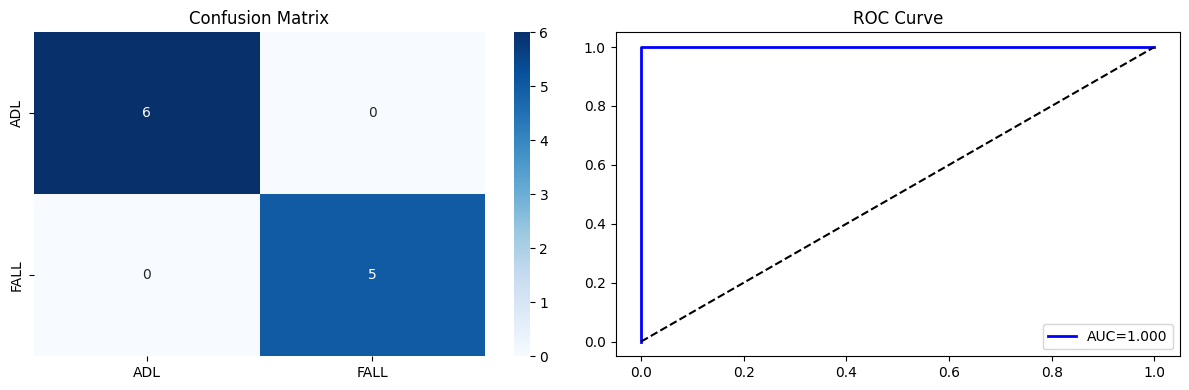

Misclassified: 0/11
Common error causes: Camera angle, Occlusion, Motion blur in rapid ADL


In [7]:
# Test evaluation: metrics + confusion matrix + ROC curve
model.eval()
with torch.no_grad():
    logits = model(X_te.to(DEVICE))
    preds = logits.argmax(1).cpu().numpy()
    probs = torch.softmax(logits, 1)[:, 1].cpu().numpy()
trues = y_te.numpy()

print("=== Test Results ===")
print(f"Accuracy: {accuracy_score(trues, preds):.4f}")
print(f"Precision: {precision_score(trues, preds, zero_division=0):.4f}")
print(f"Recall: {recall_score(trues, preds, zero_division=0):.4f}")
print(f"F1: {f1_score(trues, preds, zero_division=0):.4f}")
print(f"AUROC: {roc_auc_score(trues, probs):.4f}")
print(classification_report(trues, preds, target_names=['ADL', 'FALL']))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(confusion_matrix(trues, preds), annot=True, fmt='d', cmap='Blues', ax=a1,
            xticklabels=['ADL','FALL'], yticklabels=['ADL','FALL'])
a1.set_title("Confusion Matrix")
fpr, tpr, _ = roc_curve(trues, probs)
a2.plot(fpr, tpr, 'b-', lw=2, label=f'AUC={roc_auc_score(trues, probs):.3f}')
a2.plot([0,1],[0,1],'k--'); a2.set_title("ROC Curve"); a2.legend()
plt.tight_layout(); plt.show()

# Misclassification analysis
mis = np.where(preds != trues)[0]
print(f"Misclassified: {len(mis)}/{len(trues)}")
print("Common error causes: Camera angle, Occlusion, Motion blur in rapid ADL")
